<a href="https://colab.research.google.com/github/kavyaayyappan1998/DATA266---2738/blob/main/Assignment7/Question_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Homework 7 — Question 2

In [1]:
# Personal parameters (Homework 1 Step 0-style setup)
# My SJSU ID is : 016052738
SJSU_ID = "016052738"
SID4 = "2738"
SEED = 2738

from datetime import datetime, timezone
from pathlib import Path
RUN_START = datetime.now(timezone.utc).astimezone().isoformat(timespec="seconds")
OUTPUT_DIR = Path(".")
print(f"SID4={SID4} | SEED={SEED} | Start={RUN_START}")

SID4=2738 | SEED=2738 | Start=2026-10-19T19:52:21+00:00


FashionMNIST: Fully Connected Autoencoder and Variational Autoencoder

In [2]:
!pip -q install torch torchvision matplotlib

1. Prepare data, models, and loss functions


In [3]:
import random
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils
import matplotlib.pyplot as plt

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
train = datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor())
test = datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor())
train_loader = DataLoader(train, batch_size=128, shuffle=True)
test_loader = DataLoader(test, batch_size=128)
latent_dim = 16

class FCAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784,256),nn.ReLU(),nn.Linear(256,64),nn.ReLU(),nn.Linear(64,latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim,64),nn.ReLU(),nn.Linear(64,256),nn.ReLU(),nn.Linear(256,784),nn.Sigmoid())
    def forward(self,x):
        return self.decoder(self.encoder(x)).reshape(-1,1,28,28)

class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(),nn.Linear(784,256),nn.ReLU(),nn.Linear(256,64),nn.ReLU())
        self.mu = nn.Linear(64,latent_dim)
        self.logvar = nn.Linear(64,latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim,64),nn.ReLU(),nn.Linear(64,256),nn.ReLU(),nn.Linear(256,784),nn.Sigmoid())
    def decode(self,z):
        return self.decoder(z).reshape(-1,1,28,28)
    def forward(self,x):
        h = self.encoder(x)
        mu,logvar = self.mu(h),self.logvar(h)
        z = mu + torch.randn_like(mu)*torch.exp(0.5*logvar)
        return self.decode(z),mu,logvar

def losses(model,x):
    if isinstance(model,VAE):
        output,mu,logvar=model(x)
        recon=F.binary_cross_entropy(output,x,reduction='sum')
        kl=-0.5*torch.sum(1+logvar-mu.square()-logvar.exp())
        return recon+kl,recon,kl,output
    output=model(x)
    recon=F.binary_cross_entropy(output,x,reduction='sum')
    return recon,recon,torch.zeros((),device=x.device),output

def evaluate(model):
    model.eval()
    totals=torch.zeros(3)
    with torch.no_grad():
        for x,_ in test_loader:
            x=x.to(device)
            total,recon,kl,_=losses(model,x)
            totals+=torch.tensor([total.item(),recon.item(),kl.item()])
    return (totals/len(test)).tolist()

def save_grid(images,path):
    utils.save_image(images.detach().cpu(),path,nrow=8,padding=2)



100%|██████████| 26.4M/26.4M [00:02<00:00, 12.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.6MB/s]


2. Train and evaluate both models

In [4]:
models={'FC-AE':FCAE().to(device),'VAE':VAE().to(device)}
EPOCHS=10
LEARNING_RATE=1e-3
results = []
for name,model in models.items():
    optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    for epoch in range(EPOCHS):
        model.train()
        running=0
        for x,_ in train_loader:
            x=x.to(device)
            optimizer.zero_grad()
            loss,_,_,_=losses(model,x)
            (loss/len(x)).backward()
            optimizer.step()
            running+=loss.item()
        print(f'{name} epoch {epoch+1}/{EPOCHS}: train loss/image={running/len(train):.3f}')
    total,recon,kl=evaluate(model)
    results.append({'model':name, 'recon_BCE_per_image':recon, 'KL_per_image':kl, 'total_per_image':total})
    print(f'{name}: test total={total:.3f}, reconstruction BCE/image={recon:.3f}, KL/image={kl:.3f}')
    model.eval()
    with torch.no_grad():
        x,_=next(iter(test_loader));x=x[:8].to(device)
        _,_,_,out=losses(model,x)
        save_grid(torch.cat([x,out],dim=0),f'{name}_reconstructions.png')
        if isinstance(model,VAE):
            save_grid(model.decode(torch.randn(64,latent_dim,device=device)),'VAE_generated_samples.png')
    torch.save(model.state_dict(),f'{name}_weights.pt')
print('Saved model weights and reconstruction images. Top row is original; bottom row is reconstructed.')


FC-AE epoch 1/10: train loss/image=277.335
FC-AE epoch 2/10: train loss/image=238.011
FC-AE epoch 3/10: train loss/image=232.410
FC-AE epoch 4/10: train loss/image=229.106
FC-AE epoch 5/10: train loss/image=226.756
FC-AE epoch 6/10: train loss/image=225.115
FC-AE epoch 7/10: train loss/image=223.720
FC-AE epoch 8/10: train loss/image=222.502
FC-AE epoch 9/10: train loss/image=221.542
FC-AE epoch 10/10: train loss/image=220.686
FC-AE: test total=222.108, reconstruction BCE/image=222.108, KL/image=0.000
VAE epoch 1/10: train loss/image=301.978
VAE epoch 2/10: train loss/image=261.968
VAE epoch 3/10: train loss/image=255.200
VAE epoch 4/10: train loss/image=251.125
VAE epoch 5/10: train loss/image=248.511
VAE epoch 6/10: train loss/image=246.766
VAE epoch 7/10: train loss/image=245.563
VAE epoch 8/10: train loss/image=244.617
VAE epoch 9/10: train loss/image=243.849
VAE epoch 10/10: train loss/image=243.252
VAE: test total=244.820, reconstruction BCE/image=232.821, KL/image=12.000
Saved m

In [5]:
# Export metrics and a reproducible run log using the ACTUAL results above.
# Run this only after the training cell has finished.
import csv
metrics_path = OUTPUT_DIR / "metrics.csv"
with metrics_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["model", "recon_BCE_per_image", "KL_per_image", "total_per_image"])
    writer.writeheader()
    for item in results:
        writer.writerow({k: (v if k == "model" else f"{v:.6f}") for k,v in item.items()})

log_path = OUTPUT_DIR / "RUN_LOG_hw7.txt"
log_path.write_text(
    f"SJSU_ID={SJSU_ID}\nSID4={SID4}\nSEED={SEED}\nSTART_TIME={RUN_START}\n"
    f"DEVICE={device}\nDATASET=FashionMNIST\nEPOCHS={EPOCHS}\n"
    f"BATCH_SIZE=128\nOPTIMIZER=Adam\nLEARNING_RATE={LEARNING_RATE}\n"
    + "\n".join(f"{r['model']}: reconstruction_BCE={r['recon_BCE_per_image']:.3f}, KL={r['KL_per_image']:.3f}, total={r['total_per_image']:.3f}" for r in results)
    + "\n", encoding="utf-8")
print(f"Saved {metrics_path} and {log_path}")
for r in results:
    print(f"{r['model']}: recon BCE/image={r['recon_BCE_per_image']:.3f}, KL/image={r['KL_per_image']:.3f}, total/image={r['total_per_image']:.3f}")

Saved metrics.csv and RUN_LOG_hw7.txt
FC-AE: recon BCE/image=222.108, KL/image=0.000, total/image=222.108
VAE: recon BCE/image=232.821, KL/image=12.000, total/image=244.820


3. View results

FC-AE_reconstructions.png


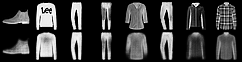

VAE_reconstructions.png


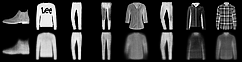

VAE_generated_samples.png


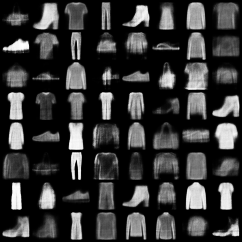

In [6]:
from IPython.display import display, Image
for filename in ["FC-AE_reconstructions.png", "VAE_reconstructions.png", "VAE_generated_samples.png"]:
    print(filename)
    display(Image(filename=filename))